In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn import svm
from sklearn.preprocessing import StandardScaler

In [6]:
df = pd.DataFrame(load_digits().data, columns=load_digits().feature_names)
df['target'] = load_digits().target
df.isnull().sum()

pixel_0_0    0
pixel_0_1    0
pixel_0_2    0
pixel_0_3    0
pixel_0_4    0
            ..
pixel_7_4    0
pixel_7_5    0
pixel_7_6    0
pixel_7_7    0
target       0
Length: 65, dtype: int64

In [14]:
x = df.drop(columns=['target'])
y = df['target']
x = StandardScaler().fit_transform(x.astype(float))

In [15]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state=42)
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((1437, 64), (360, 64), (1437,), (360,))

In [22]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score
for i in ['sigmoid', 'poly', 'rbf', 'precomputed', 'linear']:
    try:
        model = svm.SVC(kernel=i)
        model.fit(x_train, y_train)
        predict = model.predict(x_test)
        rc = recall_score(y_test, predict, average='weighted')
        f1 = f1_score(y_test, predict, average='weighted')
        acc = accuracy_score(y_test, predict)
        pre = precision_score(y_test, predict, average='weighted')
        print("kernel: ",i,"\nrecall score: ",rc,"\nf1 score: ",f1,"\naccuracy score: ",acc,"\n","precision score: ",pre, "\n")
    except Exception as e:
        print('error: ',e)

kernel:  sigmoid 
recall score:  0.9305555555555556 
f1 score:  0.931271663491378 
accuracy score:  0.9305555555555556 
 precision score:  0.9336071642563796 

kernel:  poly 
recall score:  0.9638888888888889 
f1 score:  0.965707296236171 
accuracy score:  0.9638888888888889 
 precision score:  0.9718011091685536 

kernel:  rbf 
recall score:  0.9805555555555555 
f1 score:  0.9805204312897433 
accuracy score:  0.9805555555555555 
 precision score:  0.9809087132003798 

error:  Precomputed matrix must be a square matrix. Input is a 1437x64 matrix.
kernel:  linear 
recall score:  0.975 
f1 score:  0.9749569545734269 
accuracy score:  0.975 
 precision score:  0.9752649898745233 



In [23]:
model = svm.SVC(kernel='rbf')
model.fit(x_train, y_train)
predict = model.predict(x_test)

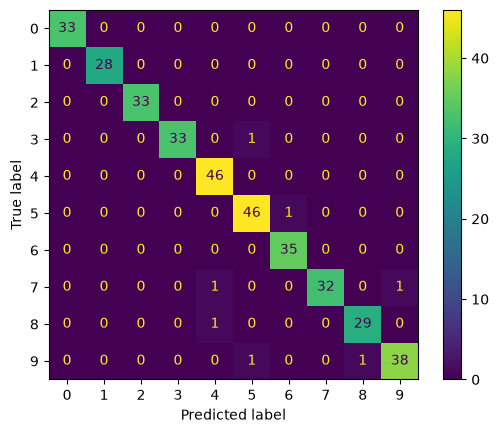

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test,  predict)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=load_digits().target_names)
display.plot()
plt.show()